# Comptage d'insectes par image (Insect Detect)

But : compter les insectes sur chaque image avec OpenCV (pas de deep learning), sur les journées d'au moins 50 images.

Plan :
1. Prise en main du dataset
2. Analyse des images
3. Analyse des ombres
4. Solution 1 : seuillage adaptatif
5. Solution 2 : soustraction de fond
6. Solution 3 : soustraction de fond + flou
7. Bilan

# 1. Prise en main du dataset

Consignes : compter par image, garder les jours avec ≥ 50 images, OpenCV seulement, doit tourner sur un PC portable. Les annotations servent seulement à évaluer, pas à détecter.

In [1]:
import os
import glob
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "."
TAILLE = 416

## 1.1 Inventaire

Chaque image a un `.txt` avec une ligne par boîte : `classe cx cy w h` (entre 0 et 1, donc × 416 pour avoir des pixels). Le jour et l'heure sont dans le nom du fichier.

In [2]:
lignes = []

for dossier in ["train", "valid", "test"]:
    liste_images = sorted(glob.glob(DATA + "/" + dossier + "/images/*.jpg"))

    for chemin in liste_images:
        nom = os.path.basename(chemin)
        chemin_txt = DATA + "/" + dossier + "/labels/" + nom.replace(".jpg", ".txt")

        boites = []
        fichier = open(chemin_txt)
        for ligne in fichier:
            morceaux = ligne.split()
            if len(morceaux) == 5:
                cx = float(morceaux[1]) * TAILLE
                cy = float(morceaux[2]) * TAILLE
                w = float(morceaux[3]) * TAILLE
                h = float(morceaux[4]) * TAILLE
                boites.append([cx, cy, w, h])
        fichier.close()

        lignes.append({"chemin": chemin,
                       "dossier": dossier,
                       "jour": nom[0:8],
                       "heure": nom[9:17],
                       "boites": boites,
                       "n": len(boites)})

tout = pd.DataFrame(lignes)

print("Nombre d'images :", len(tout))
print("Nombre de boîtes annotées :", tout["n"].sum())
print()
print("Images par jour :")
print(tout["jour"].value_counts().sort_index())

Nombre d'images : 1335
Nombre de boîtes annotées : 2132

Images par jour :
jour
20220905     11
20220906     18
20220907     32
20220908     24
20220910      1
20220911     13
20220912      3
20221006    386
20221007    114
20221008     42
20221009     12
20221010      1
20221011      1
20221012     95
20221013     18
20221014     10
20221015     19
20221016     20
20221017    107
20221018    148
20221019    185
20221020     66
20221021      9
Name: count, dtype: int64


1335 images, 2132 boîtes, 23 jours, mais beaucoup de jours avec très peu d'images.

## 1.2 Jours avec au moins 50 images

In [3]:
compte = tout["jour"].value_counts()

JOURS = []
for jour in compte.index:
    if compte[jour] >= 50:
        JOURS.append(jour)
JOURS.sort()

d = tout[tout["jour"].isin(JOURS)]
d = d.sort_values(["jour", "heure"])
d = d.reset_index(drop=True)

print("Journées retenues :", JOURS)
print("Nombre d'images :", len(d))
print("Nombre de boîtes :", d["n"].sum())
print()
print("Nombre d'images selon le nombre de boîtes :")
print(d["n"].value_counts().sort_index())
print()
print(pd.crosstab(d["jour"], d["dossier"]))

Journées retenues : ['20221006', '20221007', '20221012', '20221017', '20221018', '20221019', '20221020']
Nombre d'images : 1101
Nombre de boîtes : 1931

Nombre d'images selon le nombre de boîtes :
n
0     25
1    487
2    382
3    163
4     34
5      5
6      5
Name: count, dtype: int64

dossier   test  train  valid
jour                        
20221006    35    314     37
20221007    11     88     15
20221012     9     78      8
20221017     8     88     11
20221018    15    116     17
20221019    17    154     14
20221020     6     53      7


On garde 7 jours, 1101 images, 1931 boîtes (1,75 par image en moyenne, max 6).

Le `crosstab` montre que chaque jour est réparti entre train, valid et test. Je n'ai pas d'apprentissage, donc ce découpage ne sert pas : je travaille sur toutes les images.

# 2. Analyse des images

## 2.1 Quelques images par jour

3 images au hasard par jour, boîtes annotées en rouge.

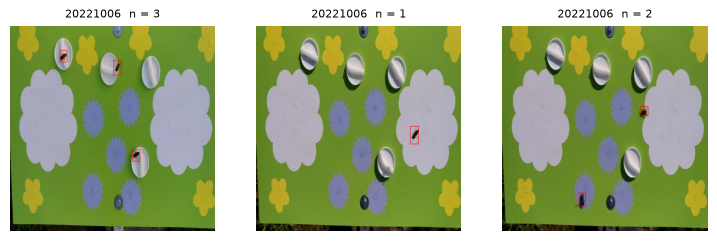

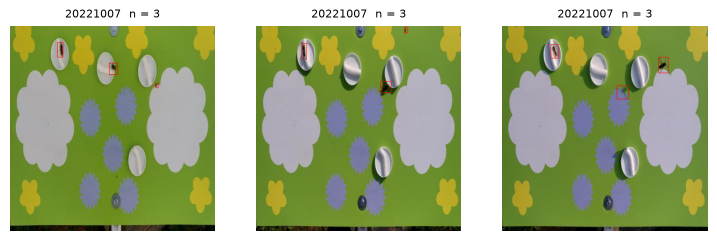

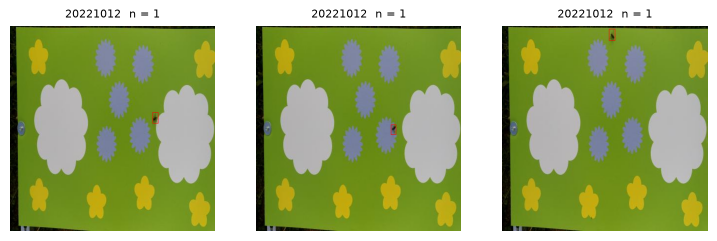

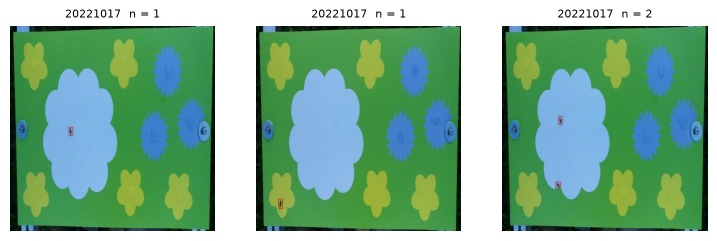

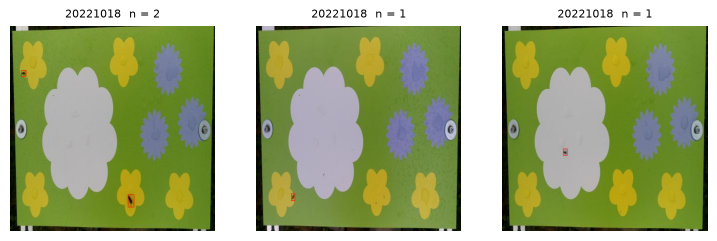

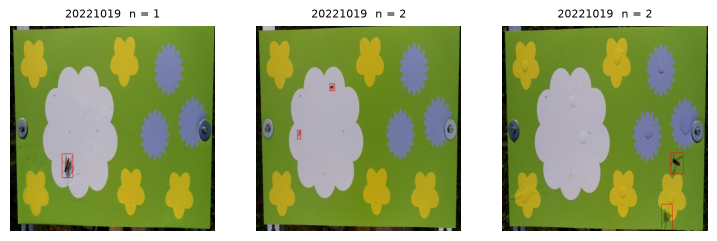

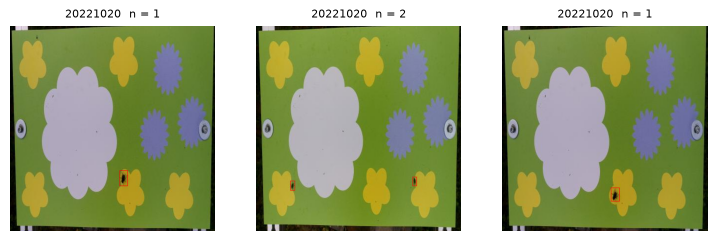

In [4]:
def lire_image(chemin):
    image = cv2.imread(chemin)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image


def dessiner_boites(image, boites):
    image = image.copy()
    for boite in boites:
        cx, cy, w, h = boite
        x1 = int(cx - w / 2)
        y1 = int(cy - h / 2)
        x2 = int(cx + w / 2)
        y2 = int(cy + h / 2)
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 1)
    return image


for jour in JOURS:
    images_du_jour = d[d["jour"] == jour]
    exemples = images_du_jour.sample(3, random_state=1)

    plt.figure(figsize=(9, 3))
    numero = 1
    for i in exemples.index:
        image = lire_image(d["chemin"][i])
        plt.subplot(1, 3, numero)
        plt.imshow(dessiner_boites(image, d["boites"][i]))
        plt.title(jour + "  n = " + str(d["n"][i]), fontsize=8)
        plt.axis("off")
        numero = numero + 1
    plt.show()

## 2.2 Contraste des boîtes annotées

Pour vérifier les annotations, je calcule pour chaque boîte un indice de contraste avec le fond autour (anneau de 6 px) :

$$\text{contraste} = 1 - \frac{P_{10}(\text{boîte})}{\text{médiane}(\text{anneau})}$$

Vers 0,8 = insecte bien noir, vers 0 = presque rien.

In [5]:
def coins(cx, cy, w, h):
    x1 = max(int(cx - w / 2), 0)
    y1 = max(int(cy - h / 2), 0)
    x2 = min(int(cx + w / 2), TAILLE)
    y2 = min(int(cy + h / 2), TAILLE)
    return x1, y1, x2, y2


def indice_contraste(gris, cx, cy, w, h):
    x1, y1, x2, y2 = coins(cx, cy, w, h)
    dedans = gris[y1:y2, x1:x2]

    # boîte agrandie de 6 pixels de chaque côté
    X1 = max(x1 - 6, 0)
    Y1 = max(y1 - 6, 0)
    X2 = min(x2 + 6, TAILLE)
    Y2 = min(y2 + 6, TAILLE)
    grand = gris[Y1:Y2, X1:X2].astype(float)

    # on retire l'intérieur : il ne reste que l'anneau
    grand[y1 - Y1:y2 - Y1, x1 - X1:x2 - X1] = np.nan

    return 1 - np.percentile(dedans, 10) / np.nanmedian(grand)


lignes_boites = []
for i in range(len(d)):
    gris = cv2.imread(d["chemin"][i], cv2.IMREAD_GRAYSCALE)
    for boite in d["boites"][i]:
        cx, cy, w, h = boite
        contraste = indice_contraste(gris, cx, cy, w, h)
        lignes_boites.append({"i": i, "cx": cx, "cy": cy, "w": w, "h": h, "contraste": contraste})

infos_boites = pd.DataFrame(lignes_boites)
print(len(infos_boites), "boîtes")
infos_boites.head()

1931 boîtes


,i,cx,cy,w,h,contraste
0,0,184.5,181.5,8.5,12.5,0.638462
1,2,12.5,245.0,6.0,11.5,0.736607
2,3,24.5,213.5,7.5,11.0,0.529518
3,4,57.5,269.0,7.0,11.0,0.526012
4,5,60.0,259.5,6.0,10.5,0.686207


Les 24 boîtes les moins contrastées :

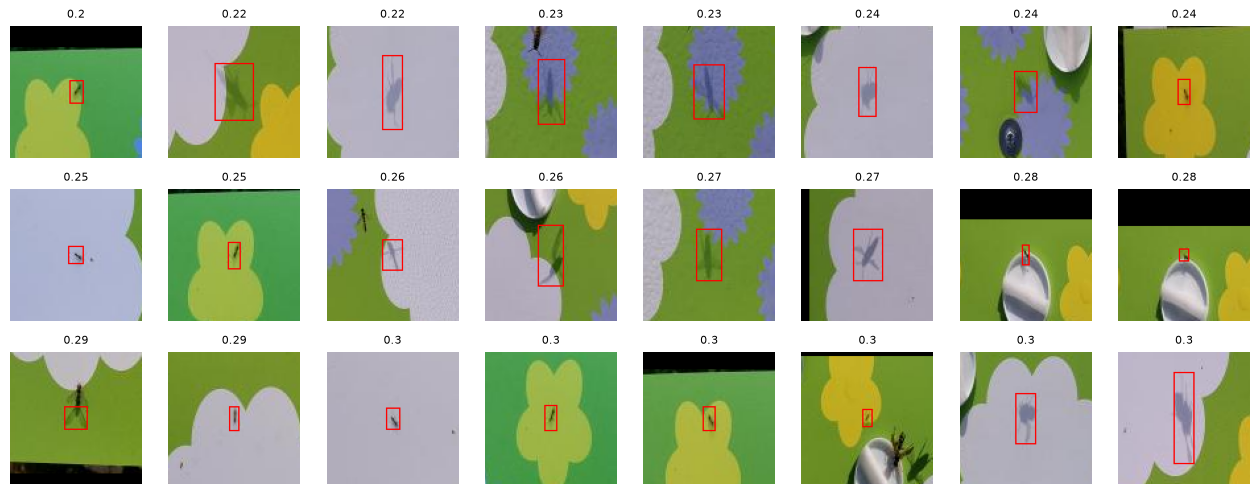

In [6]:
def vignette(i, cx, cy, w, h):
    image = lire_image(d["chemin"][i])
    image = cv2.copyMakeBorder(image, 50, 50, 50, 50, cv2.BORDER_CONSTANT)
    x = int(cx)
    y = int(cy)
    petit = image[y:y + 100, x:x + 100].copy()
    cv2.rectangle(petit, (int(50 - w / 2), int(50 - h / 2)), (int(50 + w / 2), int(50 + h / 2)), (255, 0, 0), 1)
    return petit


moins_contrastees = infos_boites.sort_values("contraste").head(24)

plt.figure(figsize=(16, 6))
numero = 1
for k in moins_contrastees.index:
    b = infos_boites.loc[k]
    plt.subplot(3, 8, numero)
    plt.imshow(vignette(int(b["i"]), b["cx"], b["cy"], b["w"], b["h"]))
    plt.title(str(round(b["contraste"], 2)), fontsize=8)
    plt.axis("off")
    numero = numero + 1
plt.show()

**Constat:** Environ la moitié sont des ombres, le reste sont des petits insectes


# 3. Analyse des ombres

Critère : une boîte est une ombre s'il y a dans la même image une boîte proche (moins de 2 hauteurs) et nettement plus contrastée (+0,12). Valeurs choisies à l'œil.

In [7]:
ombre = []

for k in infos_boites.index:
    b = infos_boites.loc[k]
    meme_image = infos_boites[infos_boites["i"] == b["i"]]

    est_ombre = False
    for j in meme_image.index:
        if j == k:
            continue
        a = infos_boites.loc[j]
        distance = np.sqrt((a["cx"] - b["cx"]) ** 2 + (a["cy"] - b["cy"]) ** 2)
        proche = distance < 2 * max(a["h"], b["h"])
        plus_contrastee = a["contraste"] > b["contraste"] + 0.12
        if proche and plus_contrastee:
            est_ombre = True

    ombre.append(est_ombre)

infos_boites["ombre"] = ombre

nb_ombres = sum(ombre)
print("Ombres repérées :", nb_ombres, "sur", len(infos_boites), "boîtes, soit",
      round(100 * nb_ombres / len(infos_boites), 1), "%")

Ombres repérées : 149 sur 1931 boîtes, soit 7.7 %


16 ombres au hasard pour vérifier :

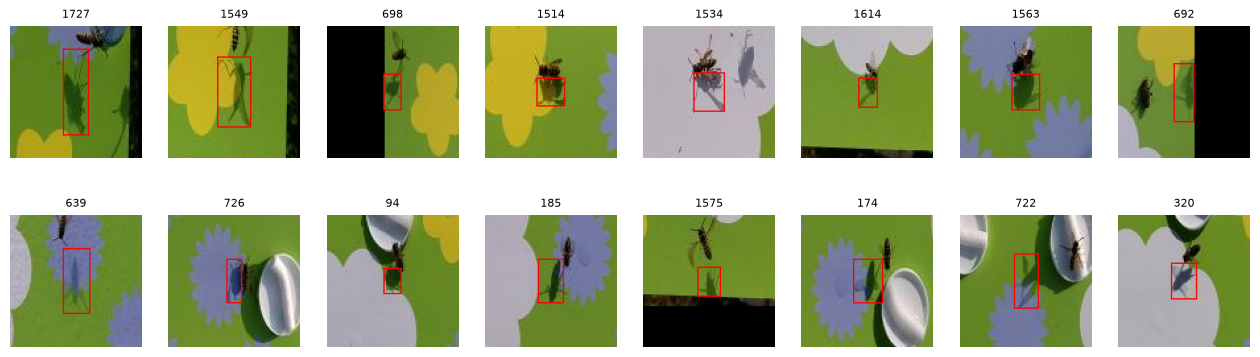

In [8]:
exemples = infos_boites[infos_boites["ombre"] == True].sample(16, random_state=1)

plt.figure(figsize=(16, 4.5))
numero = 1
for k in exemples.index:
    b = infos_boites.loc[k]
    plt.subplot(2, 8, numero)
    plt.imshow(vignette(int(b["i"]), b["cx"], b["cy"], b["w"], b["h"]))
    plt.title(str(k), fontsize=8)
    plt.axis("off")
    numero = numero + 1
plt.show()

149 ombres (7,7 %) et les 16 tirées au hasard sont bien des ombres. Le critère rate les ombres dont l'insecte n'est pas annoté à côté (par exemple hors champ), donc 149 est un minimum.

# 4. Solution 1 : seuillage adaptatif

Un insecte est plus sombre que ce qui l'entoure. Le fond change beaucoup (vert, fleurs blanches, bleues), donc un seuil fixe ne marche pas : le seuillage adaptatif calcule un seuil pour chaque pixel à partir de son voisinage.

Niveaux de gris + flou 5×5, `adaptiveThreshold` (moyenne sur un bloc 51×51, C = 20), puis `findContours`. On garde les contours de 30 à 750 px et côtés ≤ 65 px (90 % des boîtes annotées font moins de 737 px).

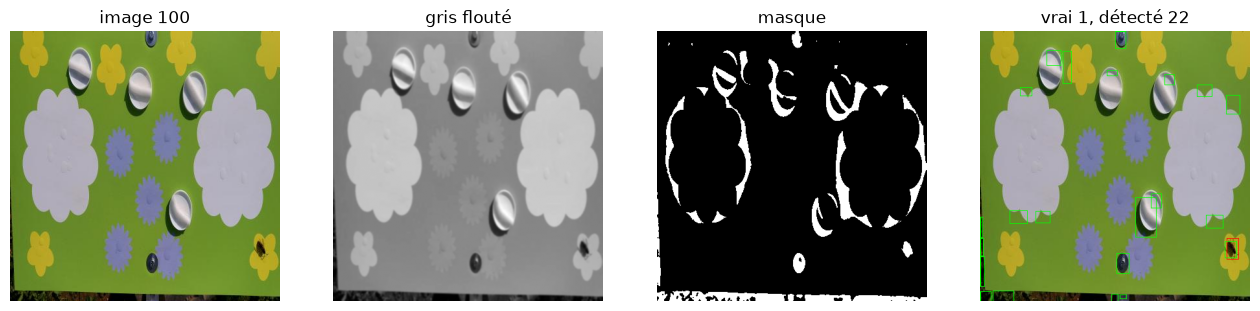

In [9]:
def afficher(i, titre, carte, masque, detections):
    image = lire_image(d["chemin"][i])
    resultat = dessiner_boites(image, d["boites"][i])
    for x, y, w, h in detections:
        cv2.rectangle(resultat, (x, y), (x + w, y + h), (0, 255, 0), 1)

    plt.figure(figsize=(16, 4))
    plt.subplot(1, 4, 1)
    plt.imshow(image)
    plt.title("image " + str(i))
    plt.axis("off")
    plt.subplot(1, 4, 2)
    plt.imshow(carte, cmap="gray")
    plt.title(titre)
    plt.axis("off")
    plt.subplot(1, 4, 3)
    plt.imshow(masque, cmap="gray")
    plt.title("masque")
    plt.axis("off")
    plt.subplot(1, 4, 4)
    plt.imshow(resultat)
    plt.title("vrai " + str(d["n"][i]) + ", détecté " + str(len(detections)))
    plt.axis("off")
    plt.show()


def solution_adaptatif(i):
    gris = cv2.cvtColor(lire_image(d["chemin"][i]), cv2.COLOR_RGB2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    masque = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 51, 20)

    contours, hierarchie = cv2.findContours(masque, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    detections = []
    for contour in contours:
        aire = cv2.contourArea(contour)
        x, y, w, h = cv2.boundingRect(contour)
        if 30 <= aire <= 750 and w <= 65 and h <= 65:
            detections.append([x, y, w, h])
    return gris, masque, detections


carte, masque, detections = solution_adaptatif(100)
afficher(100, "gris flouté", carte, masque, detections)

## Résultat de la solution 1

Mesures, avec $e_i$ = détecté − vrai :

$$\text{MAE} = \frac{1}{N}\sum |e_i| \qquad \text{biais} = \frac{1}{N}\sum e_i \qquad OA = \frac{\mathrm{Trace}(C)}{N}$$

- MAE : erreur moyenne par image ; biais : > 0 on compte trop, < 0 pas assez
- OA (cours de reconnaissance de formes) : % d'images comptées exactement, C = matrice de confusion

In [ ]:
def bilan(predit, vrai):
    erreurs = np.array(predit) - np.array(vrai)
    mae = np.mean(np.abs(erreurs))
    biais = np.mean(erreurs)
    pire = np.max(np.abs(erreurs))
    return round(mae, 3), round(biais, 3), pire


def taux_ok(predit, vrai):
    C = pd.crosstab(np.array(vrai), np.array(predit))
    classes = sorted(set(C.index) | set(C.columns))
    C = C.reindex(index=classes, columns=classes, fill_value=0).values
    return round(np.trace(C) / C.sum(), 3)


def afficher_resultat(colonne):
    mae, biais, pire = bilan(d[colonne], d["n"])
    erreurs = d[colonne] - d["n"]
    print("MAE =", mae, "  biais =", biais, "  OA =", taux_ok(d[colonne], d["n"]),
          "  erreur max =", pire, "  images avec >= 5 de trop :", np.sum(erreurs >= 5))


debut = time.time()
sol1 = []
for i in range(len(d)):
    sol1.append(len(solution_adaptatif(i)[2]))
d["sol1"] = sol1
print("temps :", round(1000 * (time.time() - debut) / len(d)), "ms par image")
afficher_resultat("sol1")

temps : 3 ms par image
MAE = 9.738   biais = 9.738   OA = 0.0   erreur max = 25   images avec >= 5 de trop : 882


- **MAE 9,7, OA 0** : aucune image n'est comptée juste, on compte toujours beaucoup trop.
- Sur l'image 100, l'insecte est bien trouvé, mais au milieu de 22 détections : bords des fleurs blanches, coupelles, vis, sol...
- Avec une seule image, on ne peut pas séparer un insecte des éléments fixes de la scène. Il faut une autre information → solution 2.

# 5. Solution 2 : soustraction de fond

La caméra est fixe et les insectes bougent. Pour chaque image, on fabrique une image **sans insectes** : la médiane des **10 images avant et 10 images après**, prises le même jour. Les fleurs, coupelles et vis sont aussi dans ce fond : en soustrayant, elles disparaissent, il reste ce qui est devenu plus sombre.

Il faut donc des images avant et après : tout le dataset est **fusionné** (train, valid et test ensemble), trié par jour et par heure.

$$A(p) = \max\Big(0,\ \frac{1}{3}\sum_{c} \big(F_c(p) - I_c(p)\big)\Big)$$

Puis binarisation (seuil 30), composantes connexes, on garde les taches ≥ 15 px.

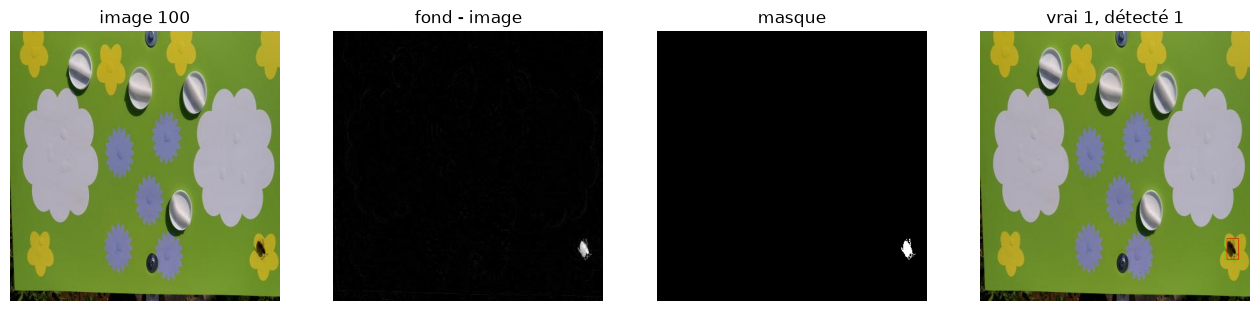

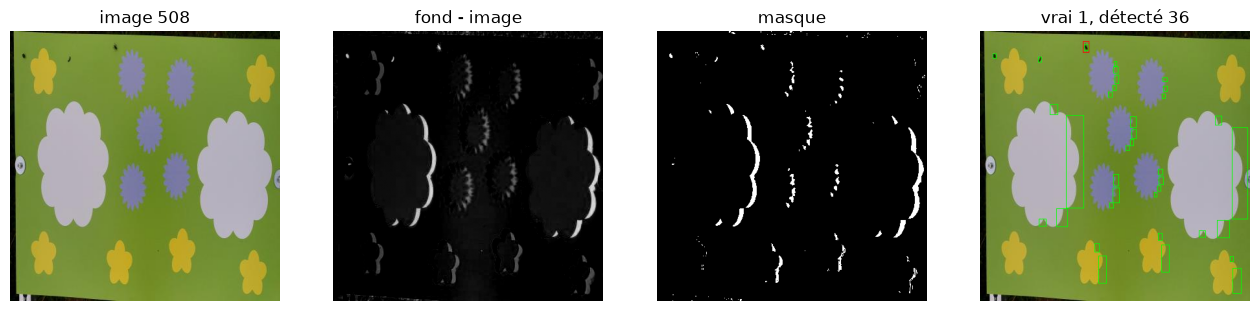

In [ ]:
SEUIL = 30
AIRE_MIN = 15
TAILLE_FLOU = 11     


def fond_median(i):
    jour = d["jour"][i]
    meme_jour = list(d[d["jour"] == jour].index)
    position = meme_jour.index(i)
    debut = max(position - 10, 0)
    fin = min(position + 11, len(meme_jour))

    pile = []
    for j in meme_jour[debut:fin]:
        if j != i:                     
            pile.append(lire_image(d["chemin"][j]))
    fond = np.median(pile, axis=0)
    return fond.astype(np.uint8)


def taches(masque, aire_min):
    nb, etiquettes, stats, centres = cv2.connectedComponentsWithStats(masque)
    detections = []
    for t in range(1, nb):              
        if stats[t, cv2.CC_STAT_AREA] >= aire_min:
            x = stats[t, cv2.CC_STAT_LEFT]
            y = stats[t, cv2.CC_STAT_TOP]
            w = stats[t, cv2.CC_STAT_WIDTH]
            h = stats[t, cv2.CC_STAT_HEIGHT]
            detections.append([x, y, w, h])
    return detections


def soustraction_fond(i, flou, fond=None):
    image = lire_image(d["chemin"][i])
    if fond is None:
        fond = fond_median(i)
    if flou:                            # solution 3
        image = cv2.GaussianBlur(image, (TAILLE_FLOU, TAILLE_FLOU), 0)
        fond = cv2.GaussianBlur(fond, (TAILLE_FLOU, TAILLE_FLOU), 0)

    # int pour avoir des négatifs (en uint8, 10 - 20 donnerait 246)
    assombri = fond.astype(int) - image.astype(int)
    assombri = assombri.mean(axis=2)
    assombri[assombri < 0] = 0

    masque = (assombri > SEUIL).astype(np.uint8)
    return assombri, masque, taches(masque, AIRE_MIN)


carte, masque, detections = soustraction_fond(100, flou=False)
afficher(100, "fond - image", carte, masque, detections)
carte, masque, detections = soustraction_fond(508, flou=False)
afficher(508, "fond - image", carte, masque, detections)

- Image 100 : 1 détection pour 1 insecte, les fleurs et les coupelles ont disparu.
- Image 508 : 36 détections pour 1 insecte. La plateforme a bougé avec le vent, les contours des fleurs ressortent.

## Résultat de la solution 

In [ ]:
debut = time.time()
sol2 = []
sol3 = []
for i in range(len(d)):
    fond = fond_median(i)
    sol2.append(len(soustraction_fond(i, False, fond)[2]))
    sol3.append(len(soustraction_fond(i, True, fond)[2]))
    if i % 200 == 0:
        print(i, "/", len(d))
d["sol2"] = sol2
d["sol3"] = sol3
print("temps :", round(1000 * (time.time() - debut) / len(d)), "ms par image (les deux versions)")
afficher_resultat("sol2")

0 / 1101
200 / 1101
400 / 1101
600 / 1101
800 / 1101
1000 / 1101
temps : 149 ms par image (les deux versions)
MAE = 2.915   biais = 2.669   OA = 0.602   erreur max = 37   images avec >= 5 de trop : 182


- **MAE 2,92, OA 0,60** : 60 % des images sont justes.
- Mais 182 images « explosent » (jusqu'à 37 détections de trop) : ce sont les images où la plateforme bouge, comme la 508.
- Limite : il faut les images d'avant et d'après, ça ne marche pas sur une photo seule.

# 6. Solution 3 : soustraction de fond + flou

Même chose, mais avec un **flou gaussien 11×11** sur l'image et sur le fond avant de soustraire. Quand la plateforme bouge d'un ou deux pixels, les bords des fleurs donnent de fines bandes : le flou les étale et elles passent sous le seuil. Un insecte, plus large et plus sombre, reste.

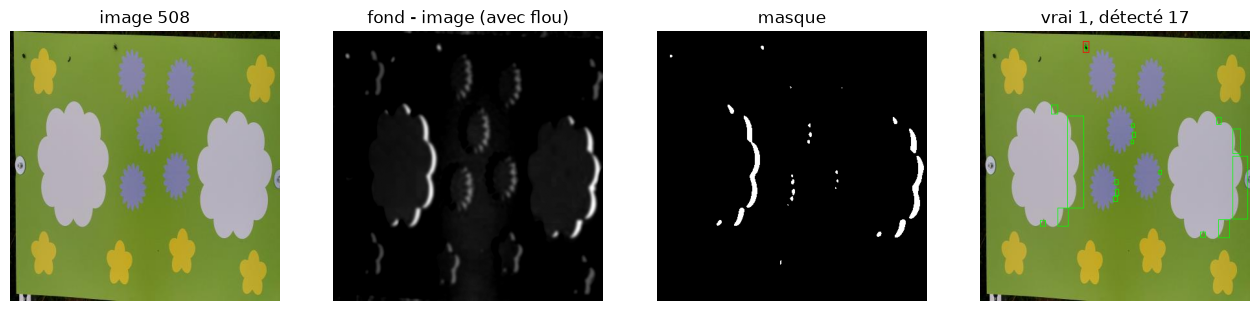

In [55]:
carte, masque, detections = soustraction_fond(508, flou=True)
afficher(508, "fond - image (avec flou)", carte, masque, detections)

Image 508 : 17 détections au lieu de 36. Les petits contours ont disparu, les grands restent.

## Résultat de la solution 3

In [14]:
afficher_resultat("sol3")

n_sans_ombres = []
for i in range(len(d)):
    n_sans_ombres.append(d["n"][i] - infos_boites[infos_boites["i"] == i]["ombre"].sum())
d["n_sans_ombres"] = n_sans_ombres
mae, biais, pire = bilan(d["sol3"], d["n_sans_ombres"])
print()
print("Matrice de confusion : vrai nombre (lignes), détecté (colonnes)")
print(pd.crosstab(d["n"], d["sol3"]))

d[["chemin", "jour", "heure", "n", "sol1", "sol2", "sol3"]].to_csv("resultats_comptage.csv", index=False)

MAE = 0.879   biais = 0.363   OA = 0.619   erreur max = 21   images avec >= 5 de trop : 56

Matrice de confusion : vrai nombre (lignes), détecté (colonnes)
sol3  0    1    2   3   4   5   6   7   8   9   10  11  12  13  14  15  16  \
n                                                                            
0     11    3    0   1   3   0   1   2   0   0   0   0   1   2   0   0   0   
1     19  385   37  14   4   0   7   6   3   0   2   3   3   0   1   0   1   
2      7  119  205  15  14   5   4   2   2   2   1   0   1   2   0   1   0   
3      0    1   73  76   2   2   1   2   4   1   0   0   0   0   1   0   0   
4      0    0   11  17   4   1   0   0   0   0   0   0   0   0   0   0   0   
5      0    0    0   3   1   0   0   0   0   0   0   0   0   1   0   0   0   
6      0    0    0   2   2   1   0   0   0   0   0   0   0   0   0   0   0   

sol3  17  19  21  
n                 
0      0   0   1  
1      2   0   0  
2      0   1   1  
3      0   0   0  
4      0   1   0  
5      0

- **MAE 0,88, biais +0,36, OA 0,62** : la MAE est divisée par plus de 3, les explosions passent de 182 à 56.
- Matrice de confusion : l'erreur la plus courante est « 2 insectes comptés 1 » (119 images), deux insectes collés font une seule tache. Le flou large aggrave un peu ça.
- Environ 0,1 s par image, ça tourne sans problème sur un portable.

# 7. Bilan

| Solution | MAE | Biais | OA | Images ≥ 5 de trop |
|---|---|---|---|---|
| 1. Seuillage adaptatif | 9,74 | +9,74 | 0,00 | 882 |
| 2. Soustraction de fond | 2,92 | +2,67 | 0,60 | 182 |
| **3. Soustraction de fond + flou 11×11** | **0,88** | **+0,36** | **0,62** | **56** |

**Retenue** : solution 3. Pas d'apprentissage, pas besoin d'annotations pour fonctionner, ~0,1 s par image.

**Ce qui ne marche pas**
- il reste des contours de fleurs détectés
- les insectes collés comptés comme un seul
- une partie des ombres est comptée, et la vérité contient elle-même au moins 149 ombres
- il faut les images voisines du même jour, pas une photo seule
- paramètres choisis à la main



**Aire maximale et seuil**

1. flou 5×5 + aire max
2. flou 7×7 + seuil de 20 à 40

- Aire max : presque aucun effet, les faux positifs sont des petits morceaux de contours.
- Seuil : seuil bas = meilleur OA, seuil haut = meilleure MAE (0,76 à 40). Jamais les deux en même temps.

Les contours dus au mouvement ont le même contraste que les insectes pâles, donc le seuil ne peut pas les séparer.

Essai 1 : flou 5x5, seuil 30
                   essai   MAE  biais  erreur max    OA  images >= 5 de trop  images avec 1 de moins
           aucune limite 1.399  1.101          33 0.650                   87                     134
            aire <= 2000 1.389  1.089          33 0.650                   87                     135
            aire <= 1000 1.378  1.078          33 0.650                   87                     135
             aire <= 750 1.368  1.068          33 0.650                   87                     135
aire <= 750, côtés <= 65 1.276  0.973          30 0.649                   80                     135
aire <= 500, côtés <= 65 1.274  0.933          30 0.647                   75                     138

Essai 2 : flou 7x7, sans limite d'aire
   essai   MAE  biais  erreur max    OA  images >= 5 de trop  images avec 1 de moins
seuil 20 1.976  1.755          50 0.655                  128                      99
seuil 25 1.367  1.073          35 0.657               